In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "examples/diffusion/config.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from IPython.display import display

from examples.diffusion.config import RESULT_DIR
from examples.diffusion.analysis.comparison import (
    load_comparison,
    run_all_comparisons,
)
from examples.diffusion.analysis.plot import (
    has_dataset_type,
    load_runs,
    plot_gold_pmp_overview,
    plot_metric_grid,
    plot_pmp_recovery,
    plot_pmp_surprise_grid,
    summarize_runs,
)


In [ ]:
RESULT_ROOT = RESULT_DIR
OUTPUT_ROOT = RESULT_ROOT / "plots" / "n384"

SUMMARY_MULTIPLIERS = (1, 2, 4)
SCORING_RULES = ("cross_entropy", "logistic", "exponential")
DATASET_TYPE = "both"  # "both", "simulated", or "empirical"

# Existing comparison CSVs are already complete, so keep this False for normal plotting.
BUILD_COMPARISONS = False
OVERWRITE_COMPARISONS = False
CONVERGENCE_POLICY = "available"

LOESS_FRAC = 1  # one pooled fit across simulated + empirical when DATASET_TYPE="both"
LOESS_SPACE = "symlog"
DPI = 220


In [3]:
if BUILD_COMPARISONS:
    run_all_comparisons(
        summary_multipliers=SUMMARY_MULTIPLIERS,
        scoring_rules=SCORING_RULES,
        splits=("simulated", "empirical"),
        result_dir=RESULT_ROOT,
        convergence_policy=CONVERGENCE_POLICY,
        allow_missing_empirical=False,
        overwrite=OVERWRITE_COMPARISONS,
    )


## Load comparison tables


In [4]:
indirect_runs = load_runs(
    "indirect",
    summary_multipliers=SUMMARY_MULTIPLIERS,
    result_dir=RESULT_ROOT,
)
direct_runs = load_runs(
    "direct",
    scoring_rules=SCORING_RULES,
    result_dir=RESULT_ROOT,
)

display(summarize_runs(indirect_runs))
display(summarize_runs(direct_runs))


,run,method,rows,datasets,simulated,empirical,summary_multiplier,scoring_rule
0,S=D,indirect,544,136,119,17,1,
1,S=2D,indirect,544,136,119,17,2,
2,S=4D,indirect,544,136,119,17,4,


,run,method,rows,datasets,simulated,empirical,summary_multiplier,scoring_rule
0,Cross-entropy,direct,544,136,119,17,0,cross_entropy
1,Logistic,direct,544,136,119,17,0,logistic
2,Exponential,direct,544,136,119,17,0,exponential


## Indirect: posterior MMD vs diagnostic score


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/posterior_mmd_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/posterior_mmd_4x4.pdf


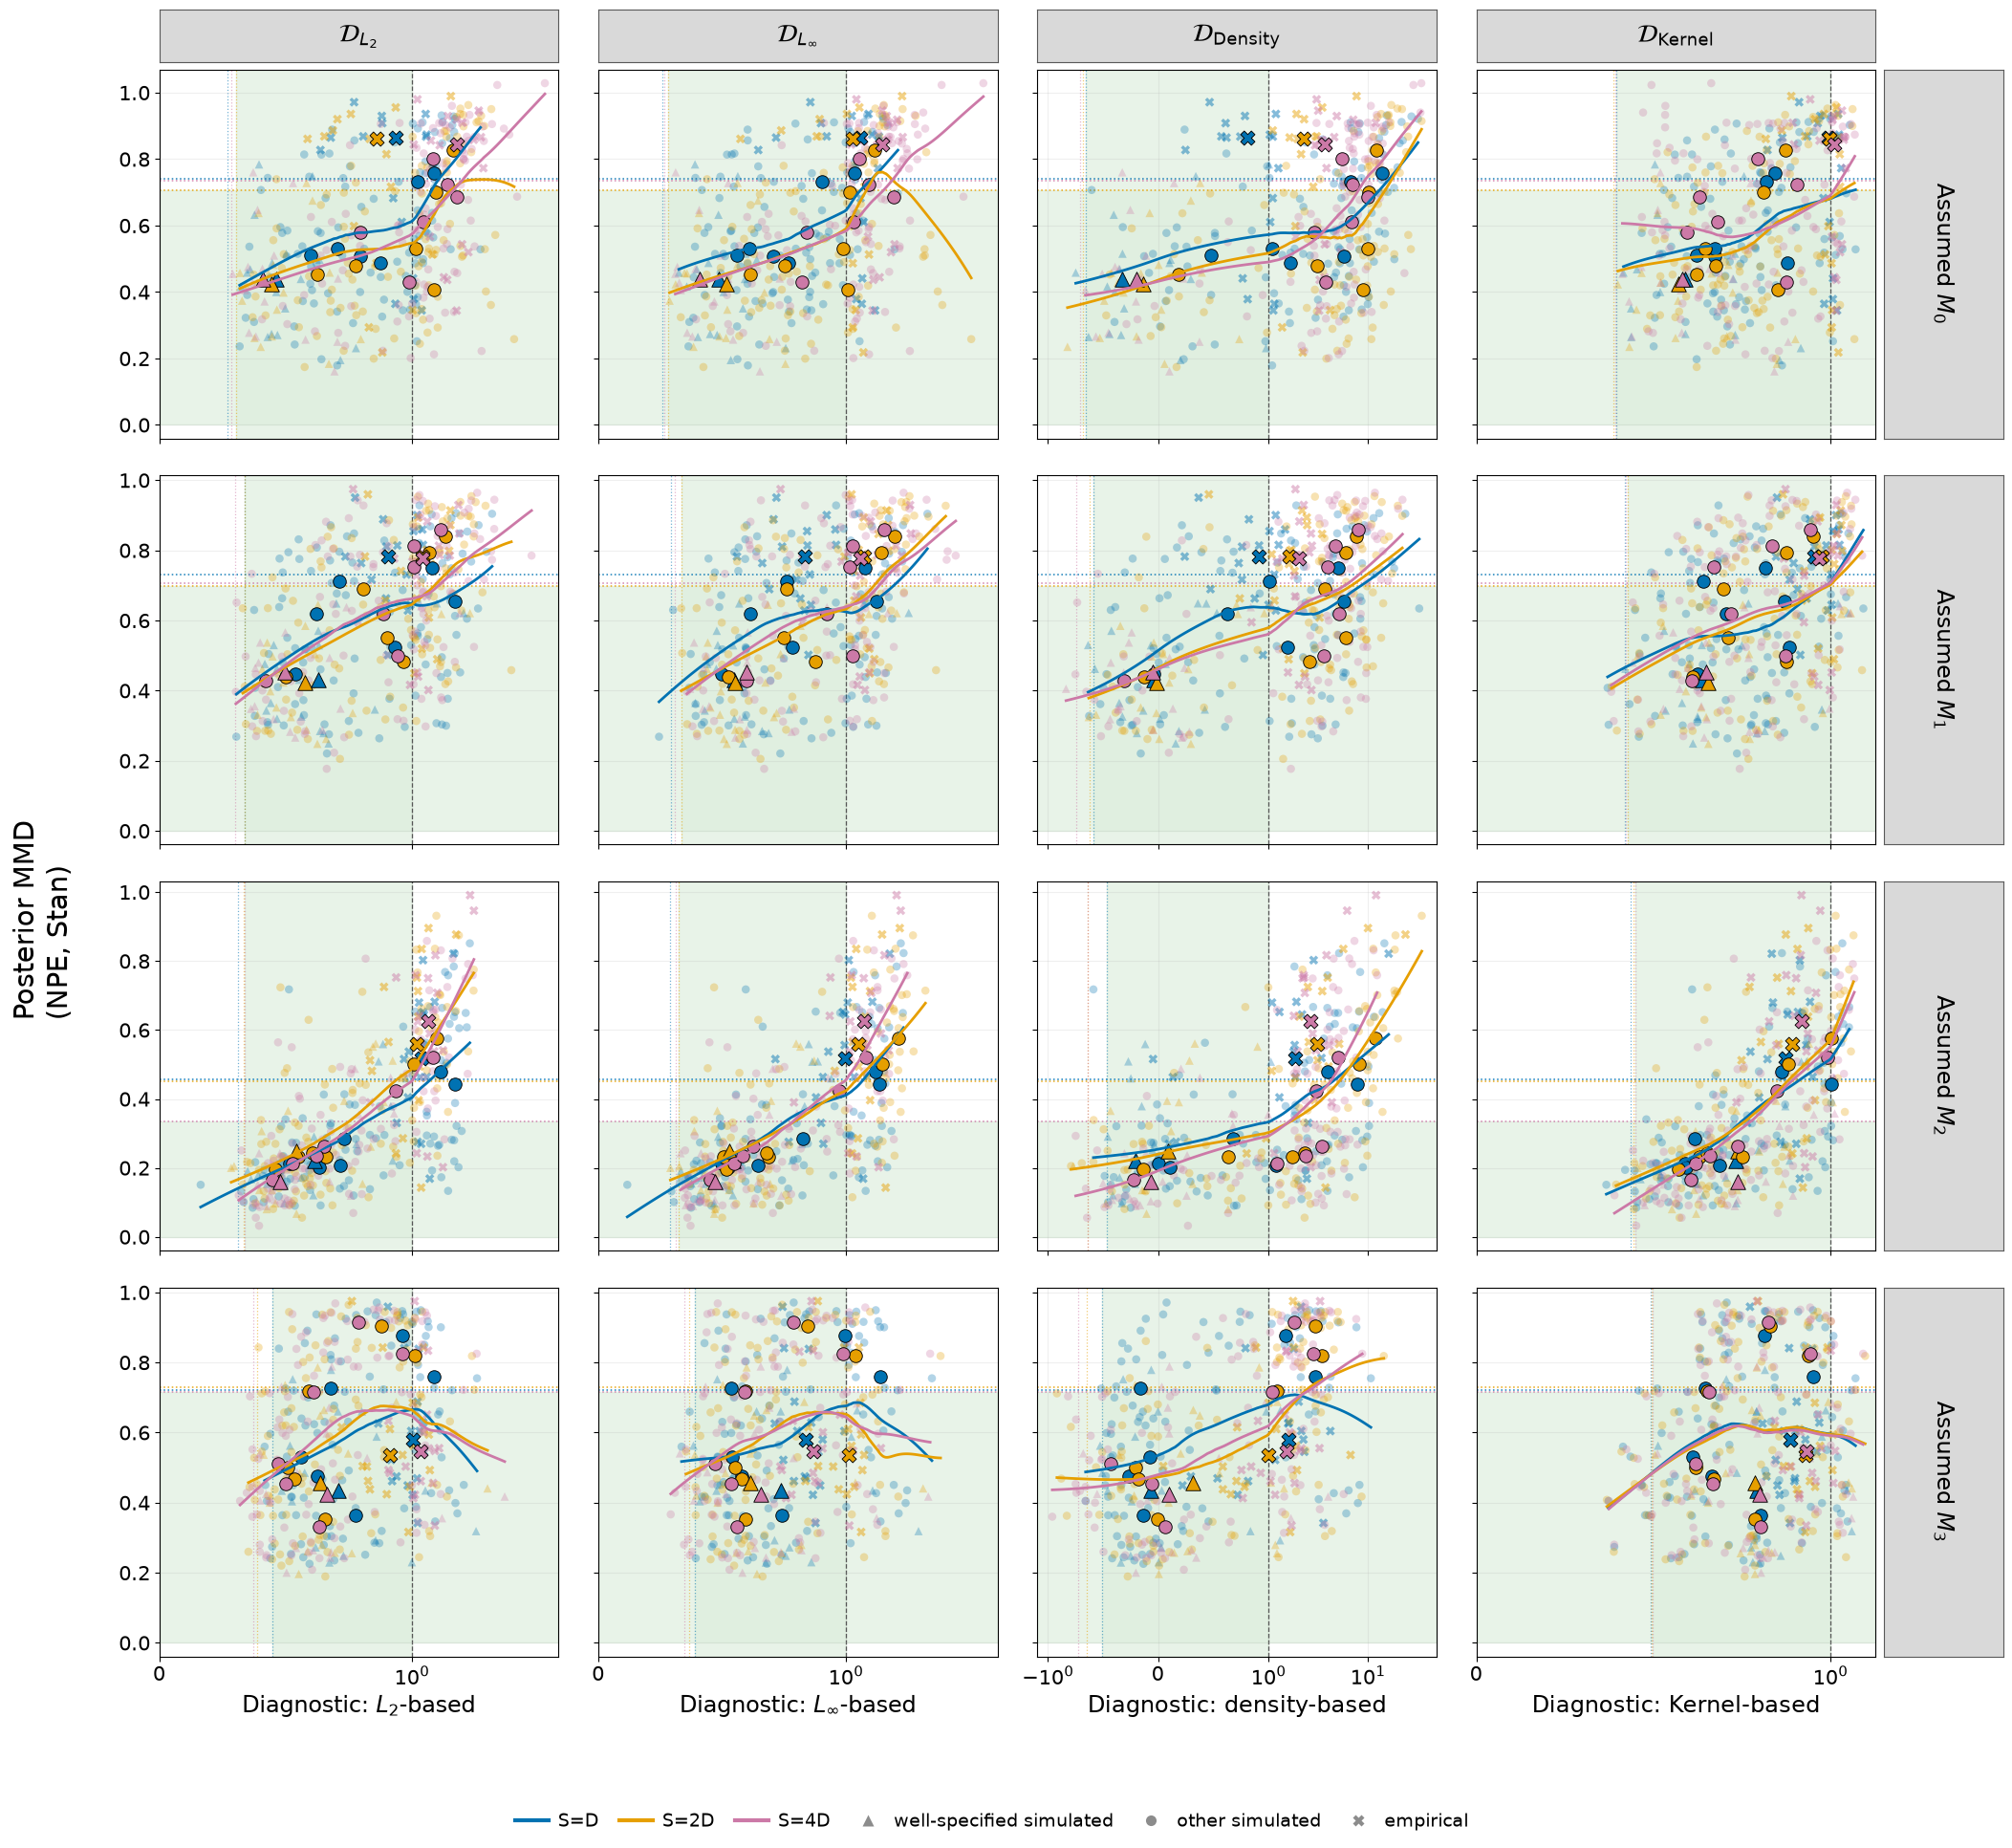

In [5]:
fig_mmd, axes_mmd = plot_metric_grid(
    indirect_runs,
    "posterior_mmd",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "posterior_mmd_4x4",
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    dpi=DPI,
)
plt.show()


## Indirect: log marginal-likelihood error vs diagnostic score


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/logml_error_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/logml_error_4x4.pdf


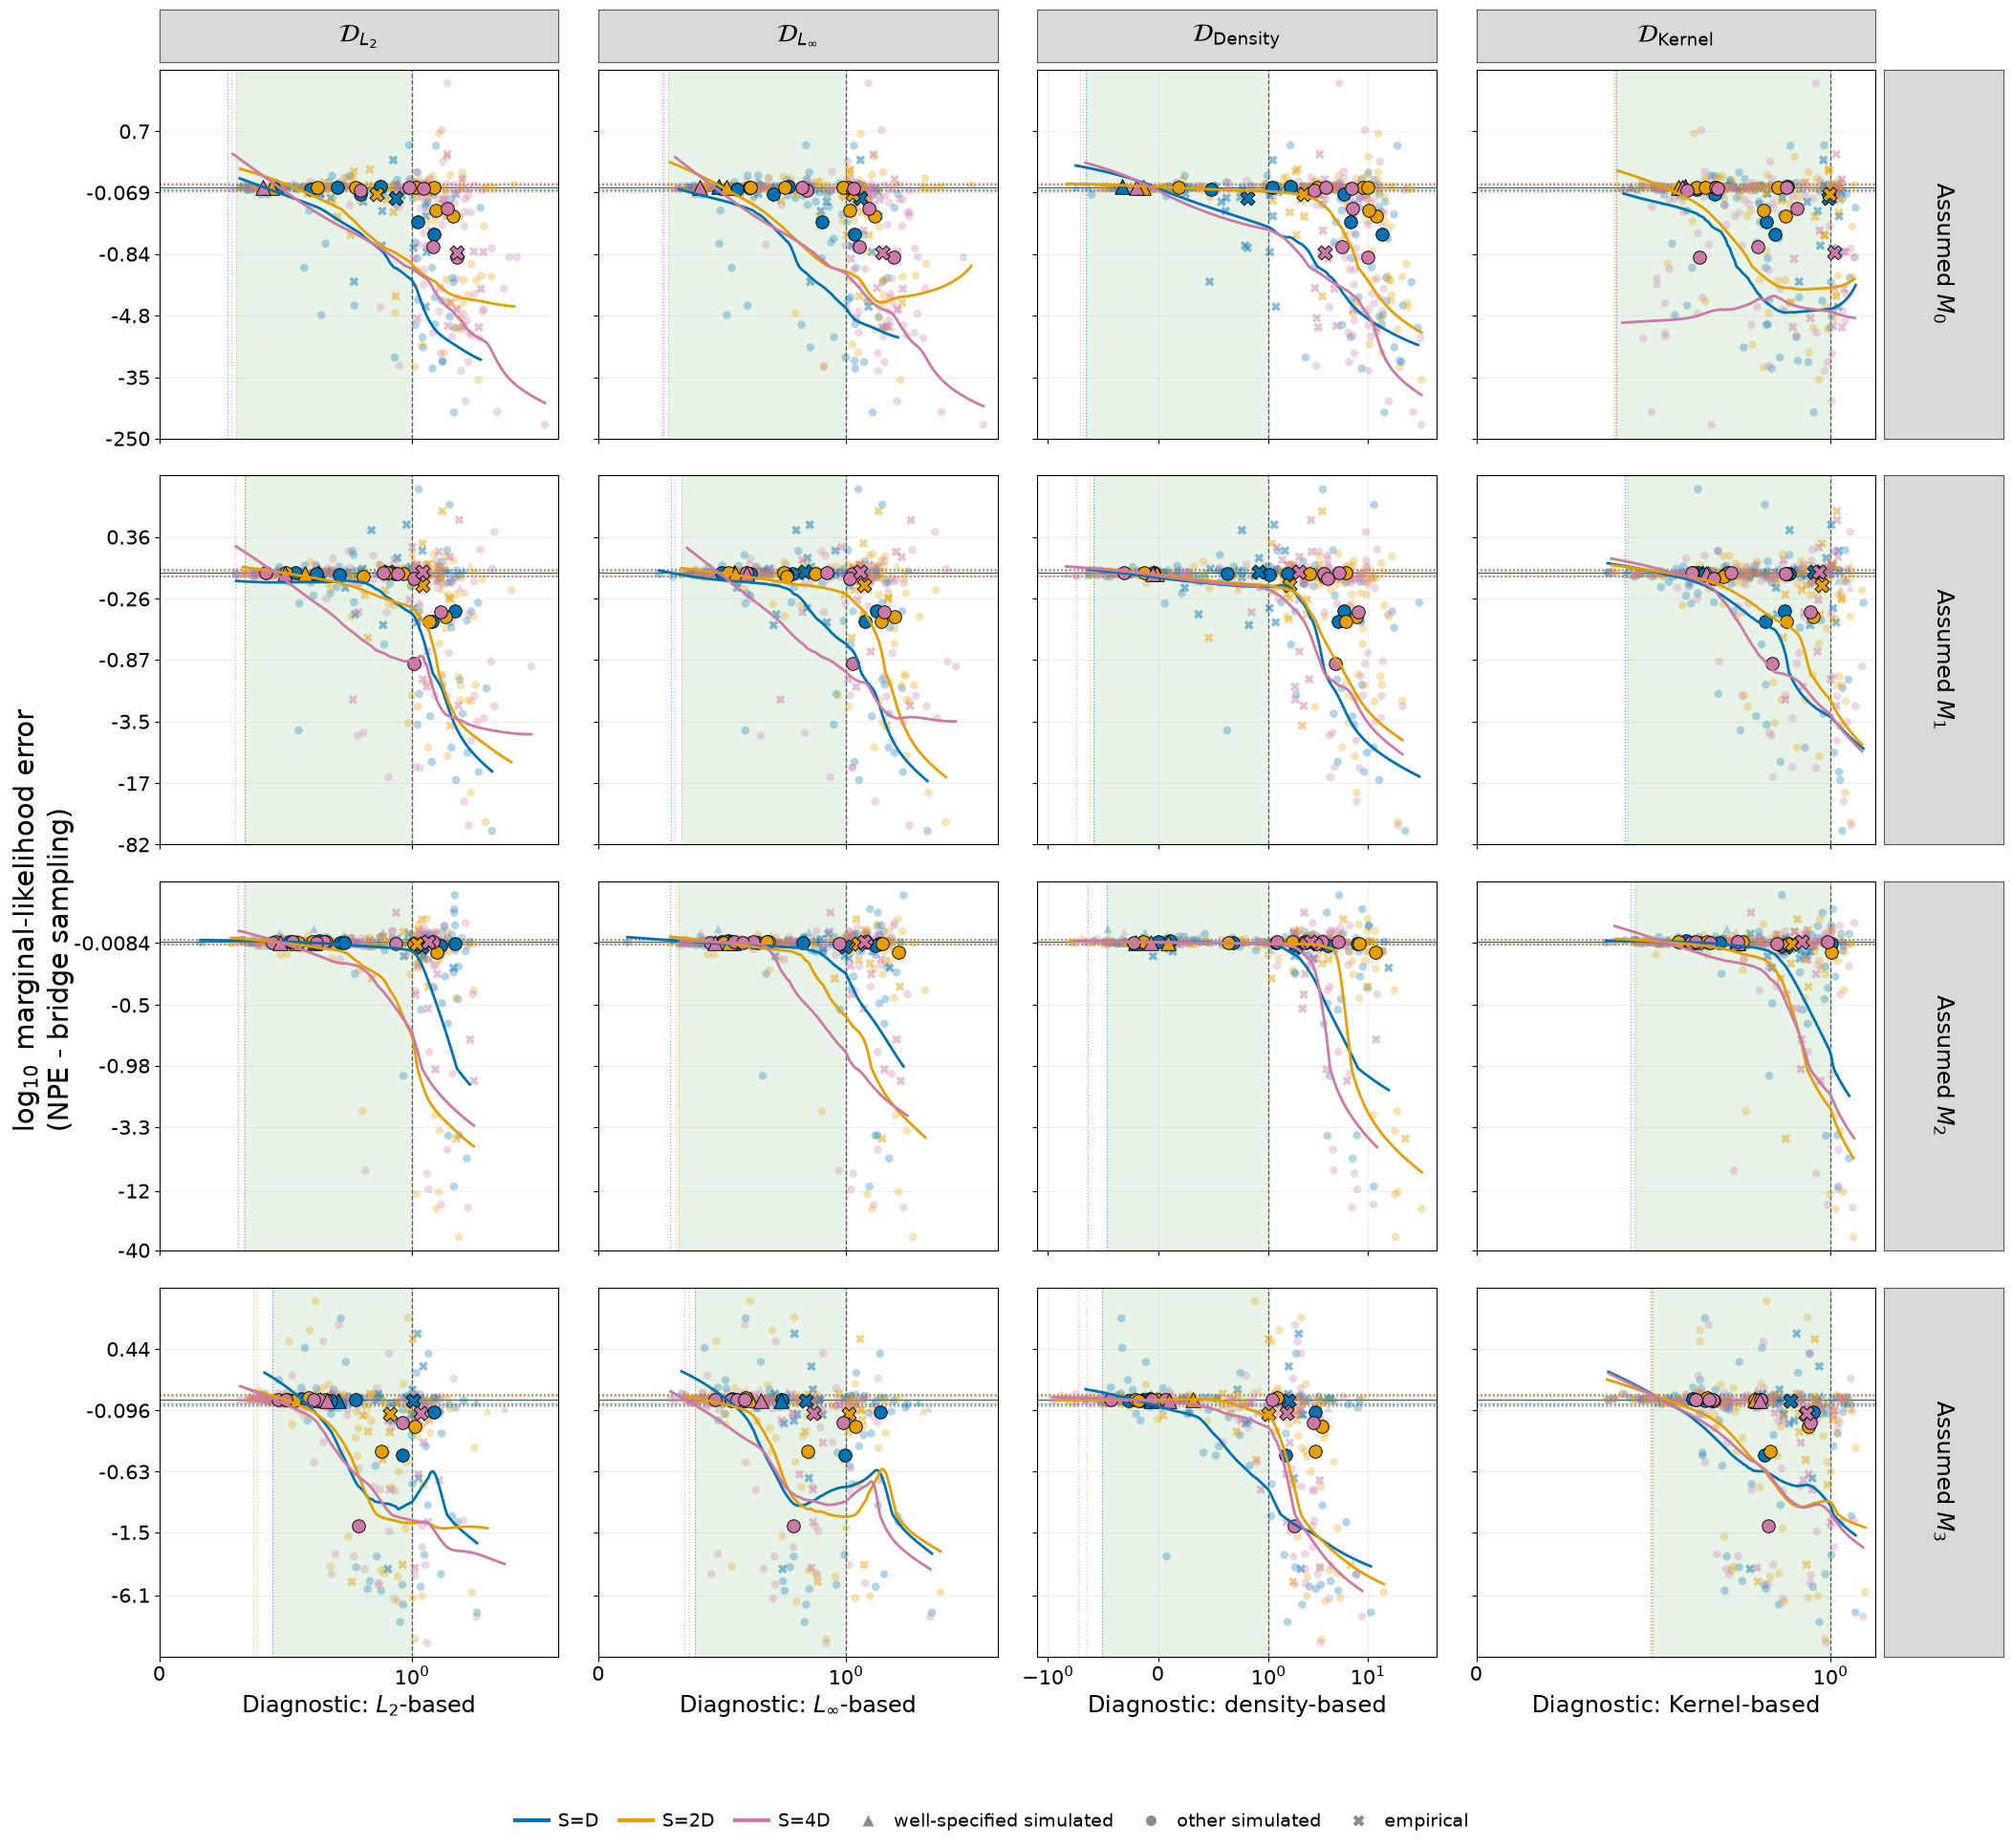

In [6]:
fig_logml, axes_logml = plot_metric_grid(
    indirect_runs,
    "logml",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "logml_error_4x4",
    yscale="symlog",
    y_linthresh=1.0,
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    dpi=DPI,
)
plt.show()


## Indirect: candidate-specific PMP error vs diagnostic score


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/pmp_error_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/both/pmp_error_4x4.pdf


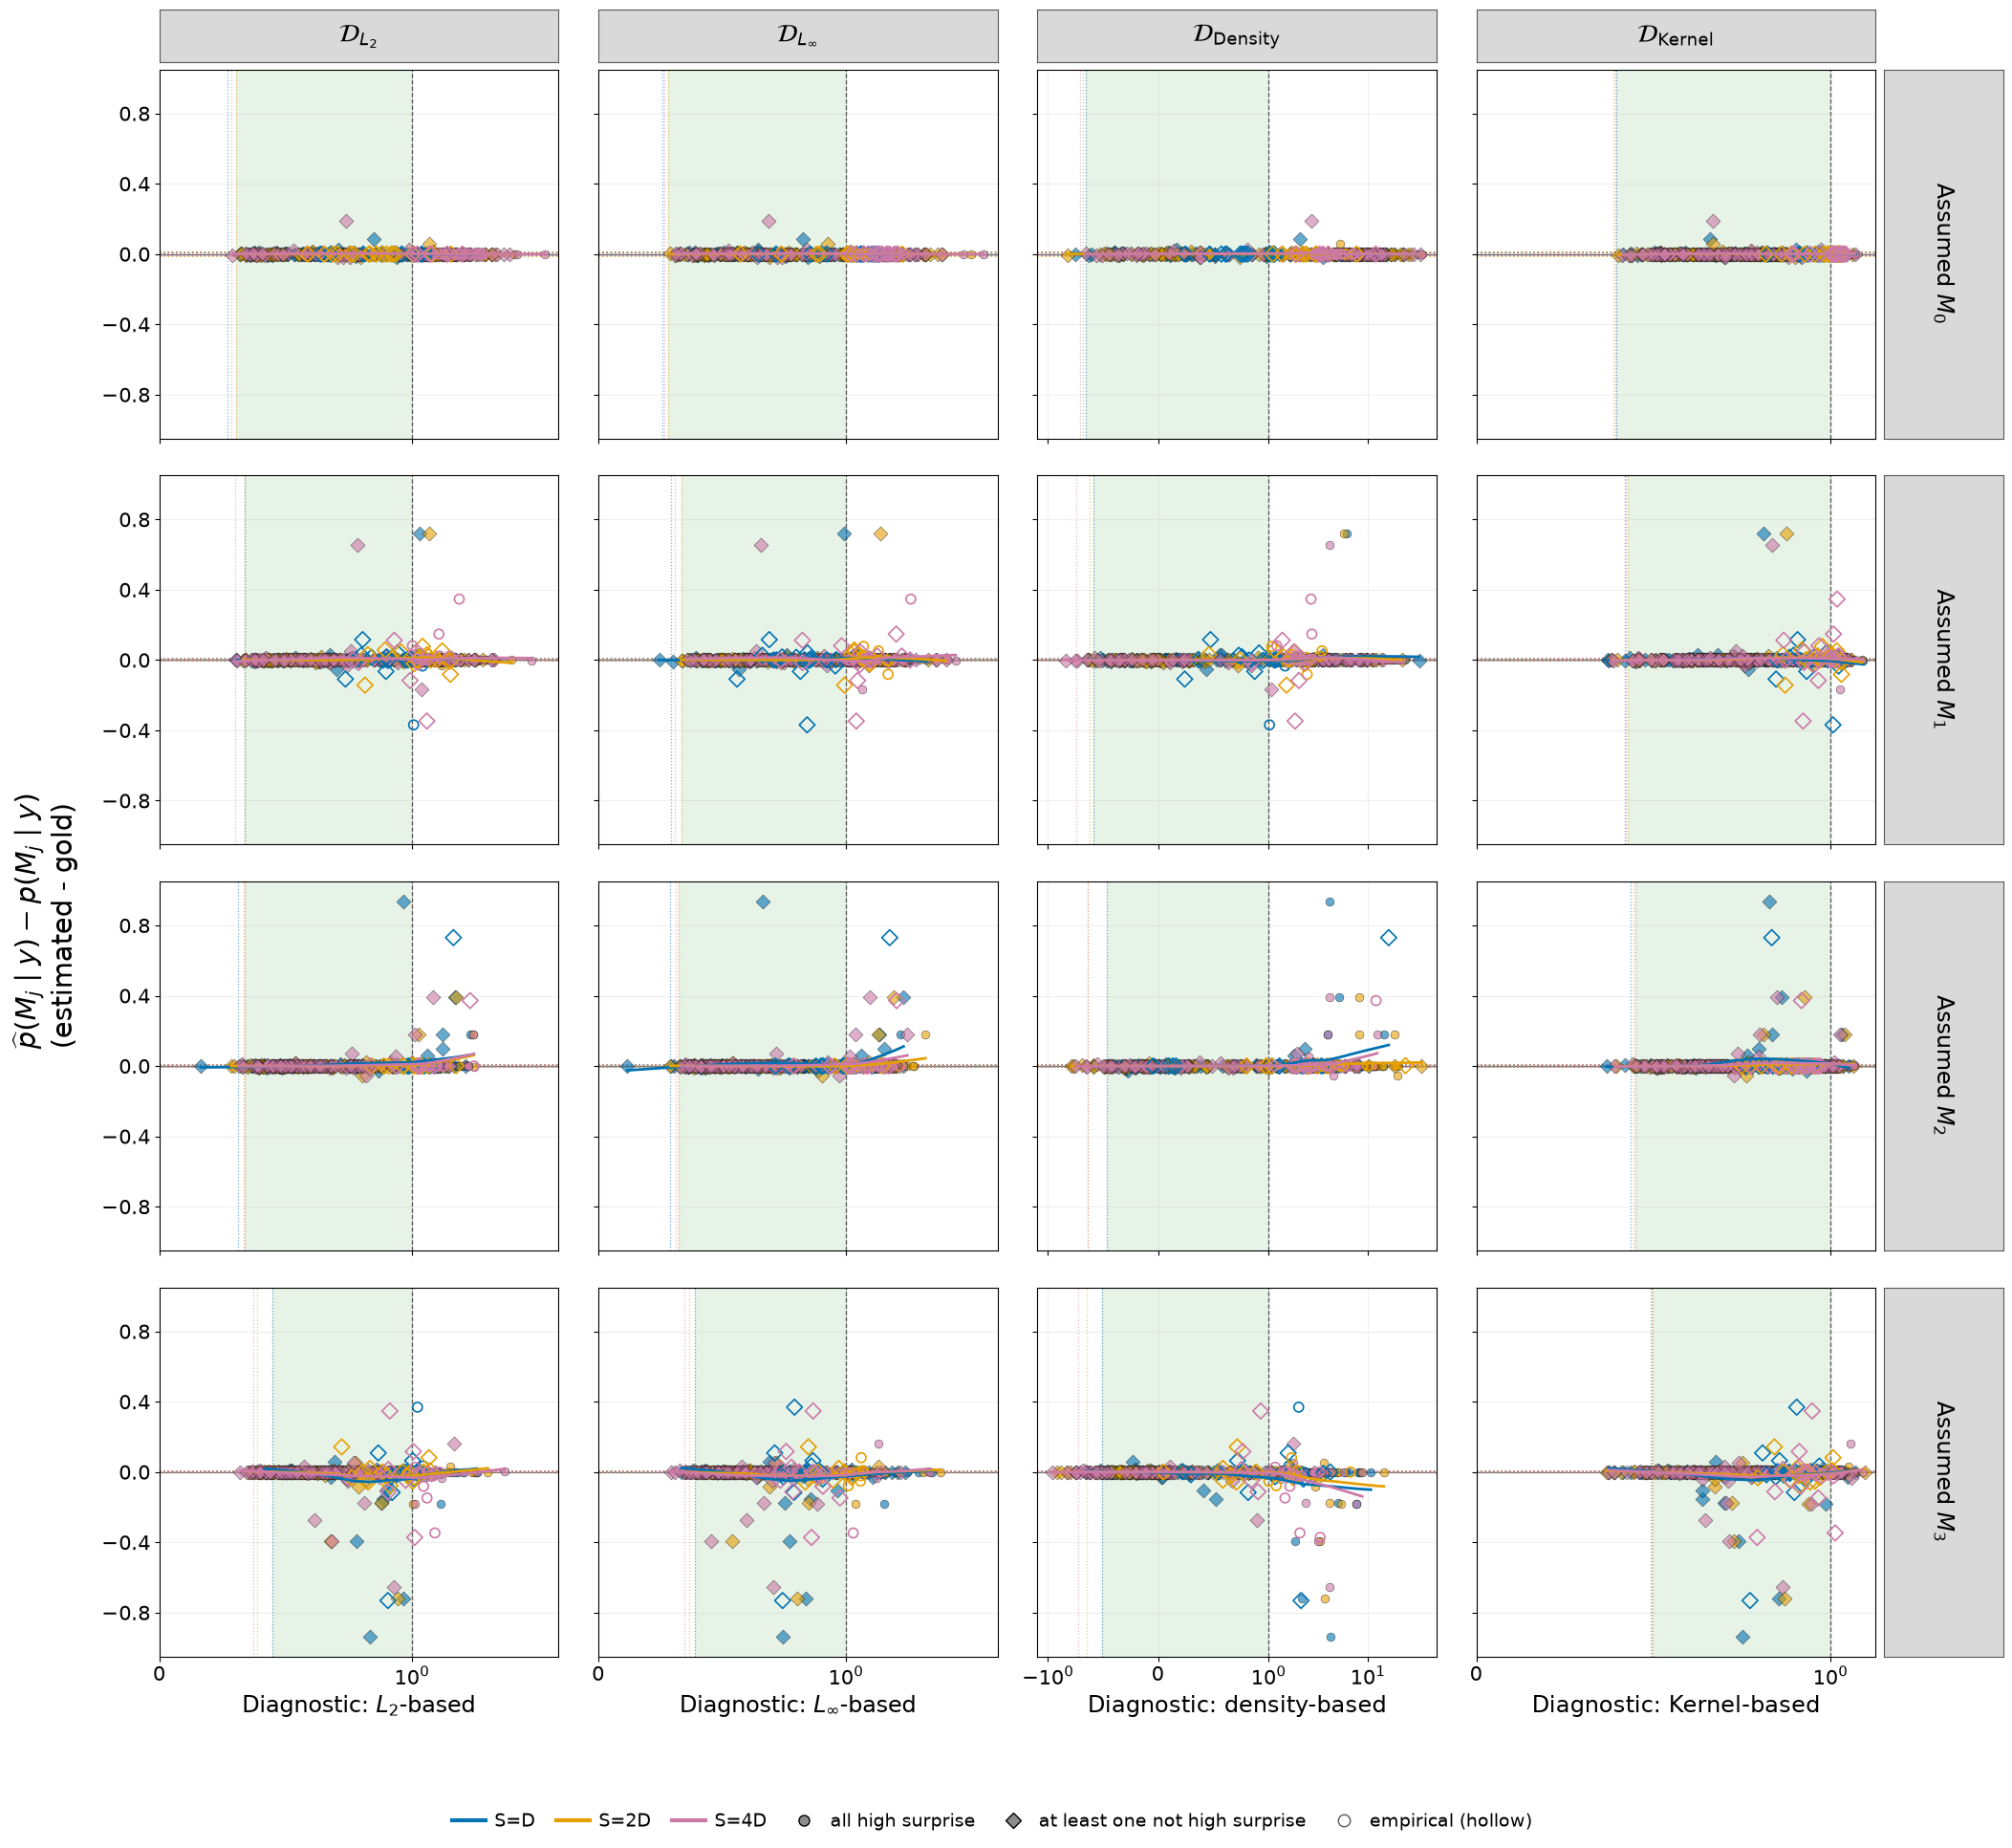

In [7]:
fig_pmp, axes_pmp = plot_metric_grid(
    indirect_runs,
    "pmp",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "pmp_error_4x4",
    ylim=(-1.05, 1.05),
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    dpi=DPI,
)
plt.show()


## Empirical PMP error colored by gold-standard PMP


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/empirical/gold_pmp_8x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/indirect/empirical/gold_pmp_8x4.pdf


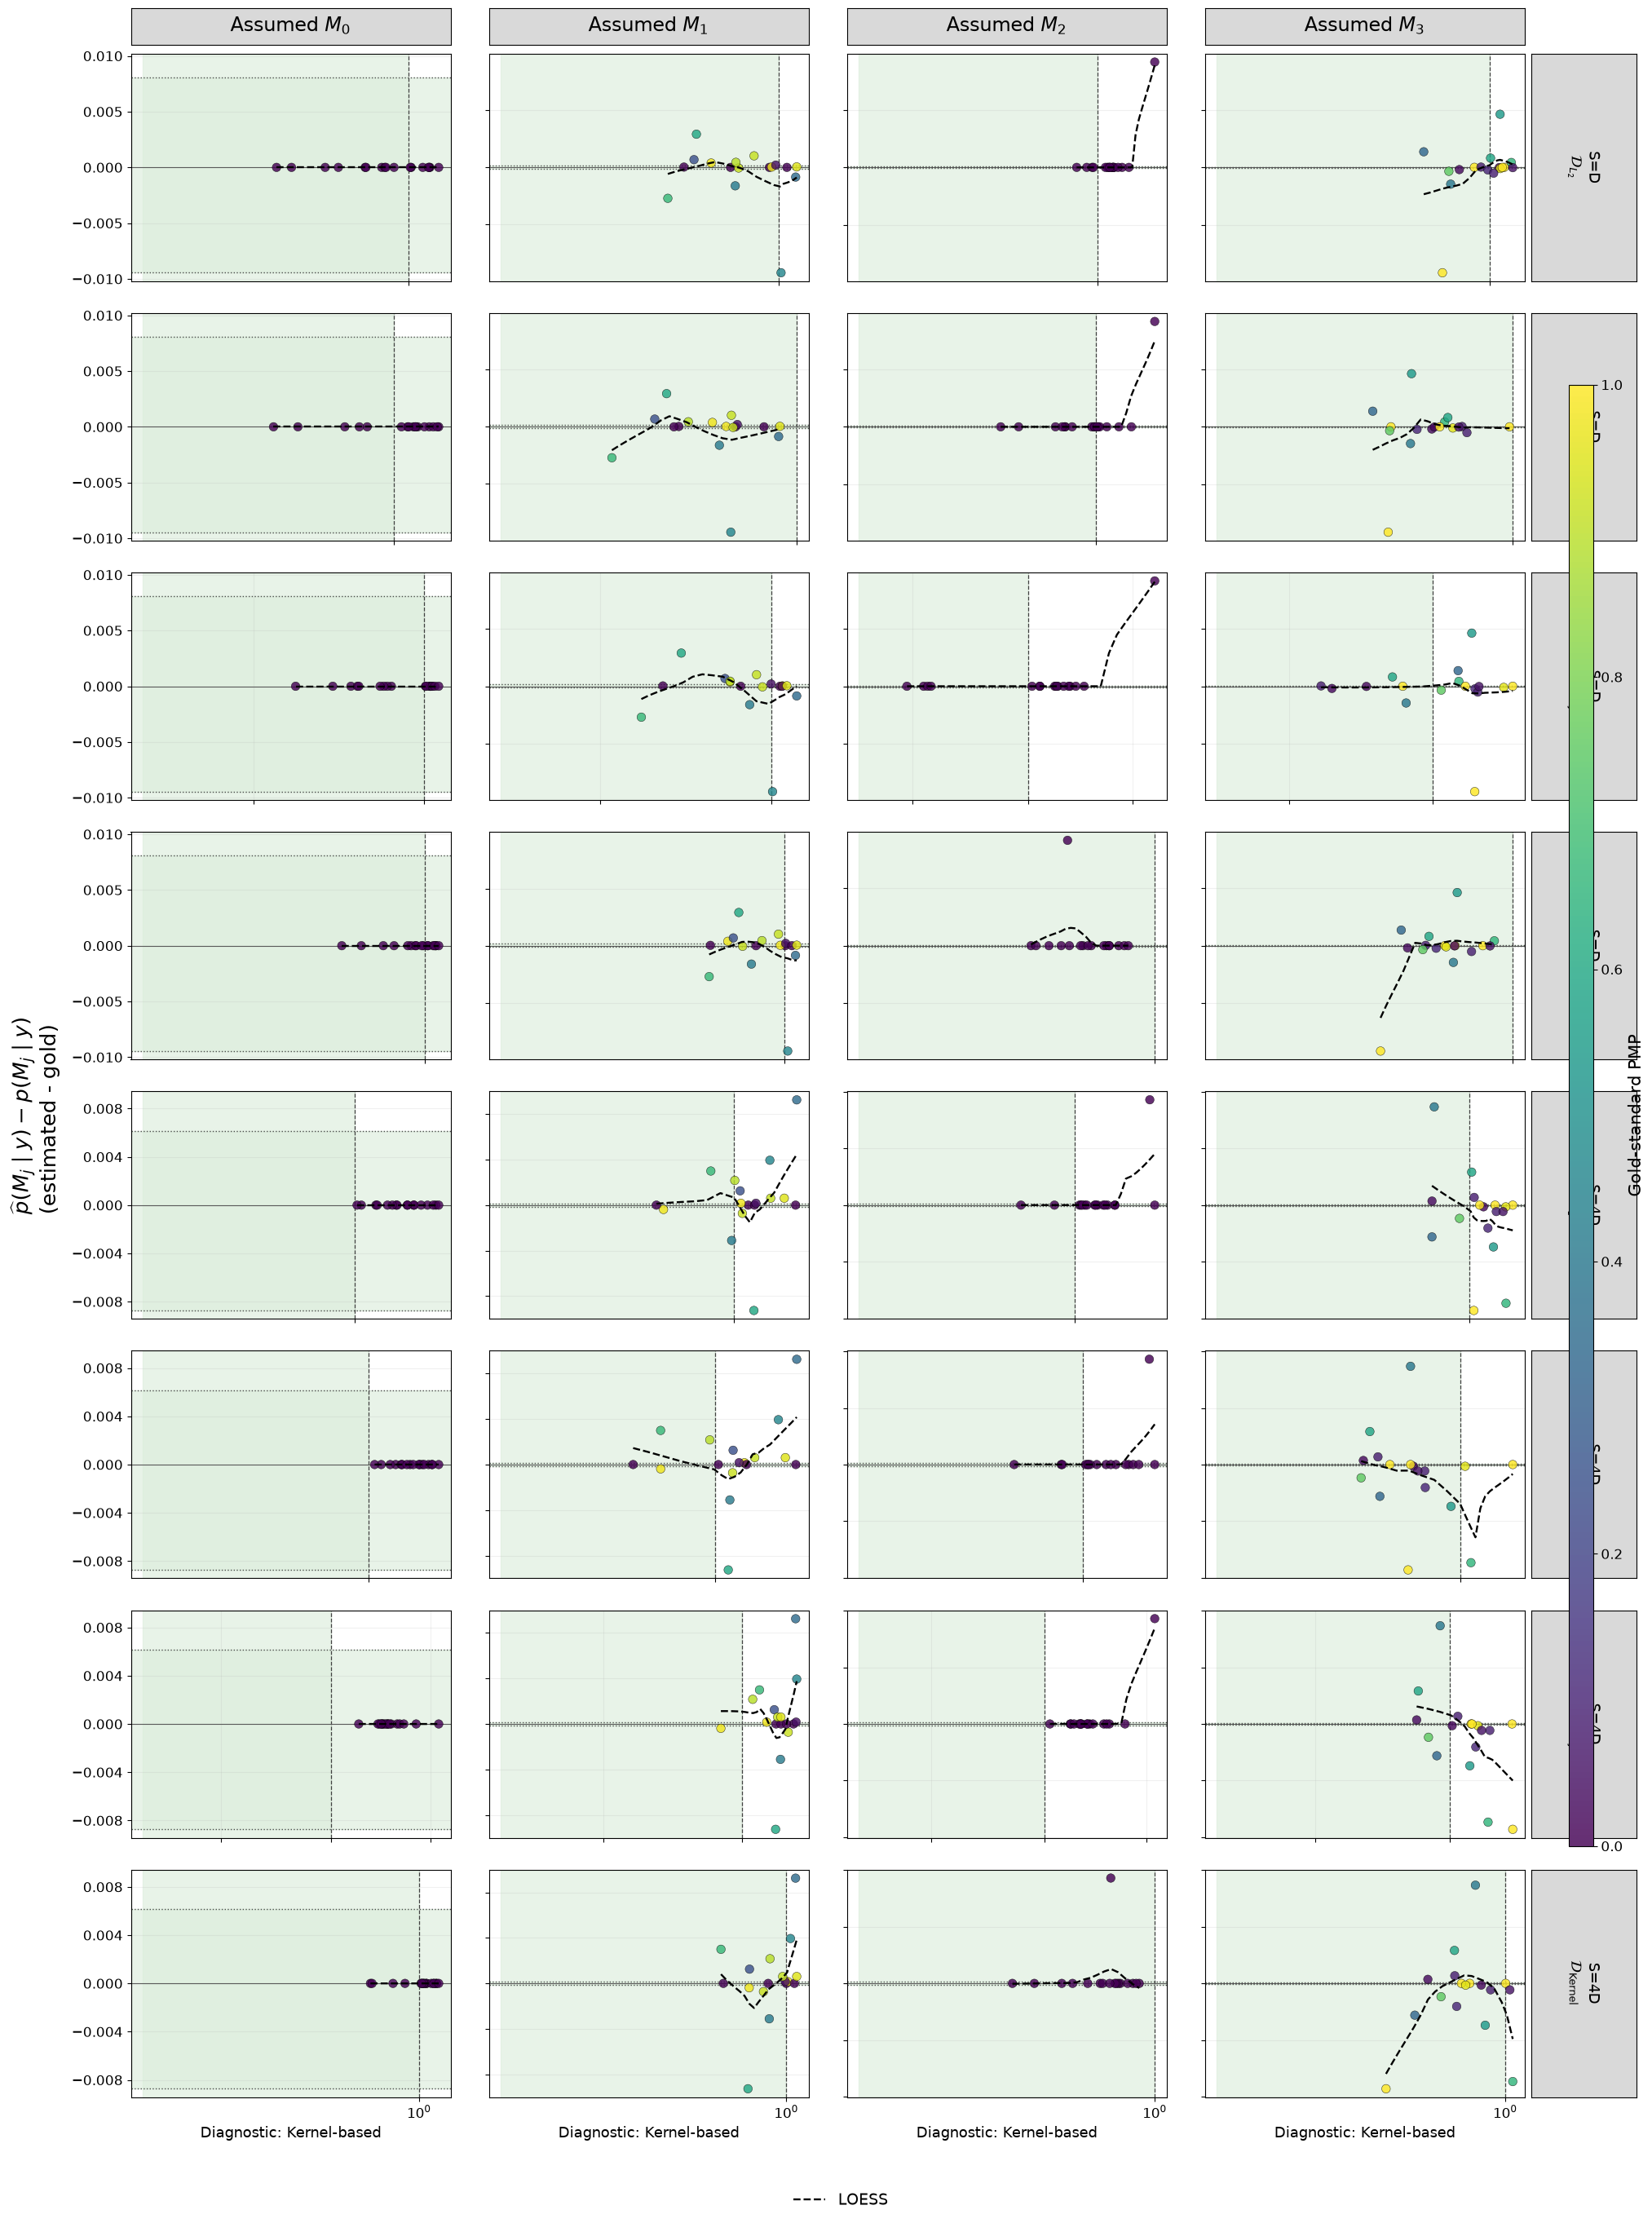

In [8]:
if has_dataset_type(indirect_runs, "empirical"):
    fig_gold, axes_gold = plot_gold_pmp_overview(
        indirect_runs,
        summary_multipliers=(1, 4),
        dataset_type="empirical",
        output=OUTPUT_ROOT / "indirect" / "empirical" / "gold_pmp_8x4",
        loess_frac=0.7,
        loess_space=LOESS_SPACE,
        dpi=DPI,
    )
    plt.show()


## Direct: PMP error vs shared diagnostic score


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/direct/both/pmp_error_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/direct/both/pmp_error_4x4.pdf


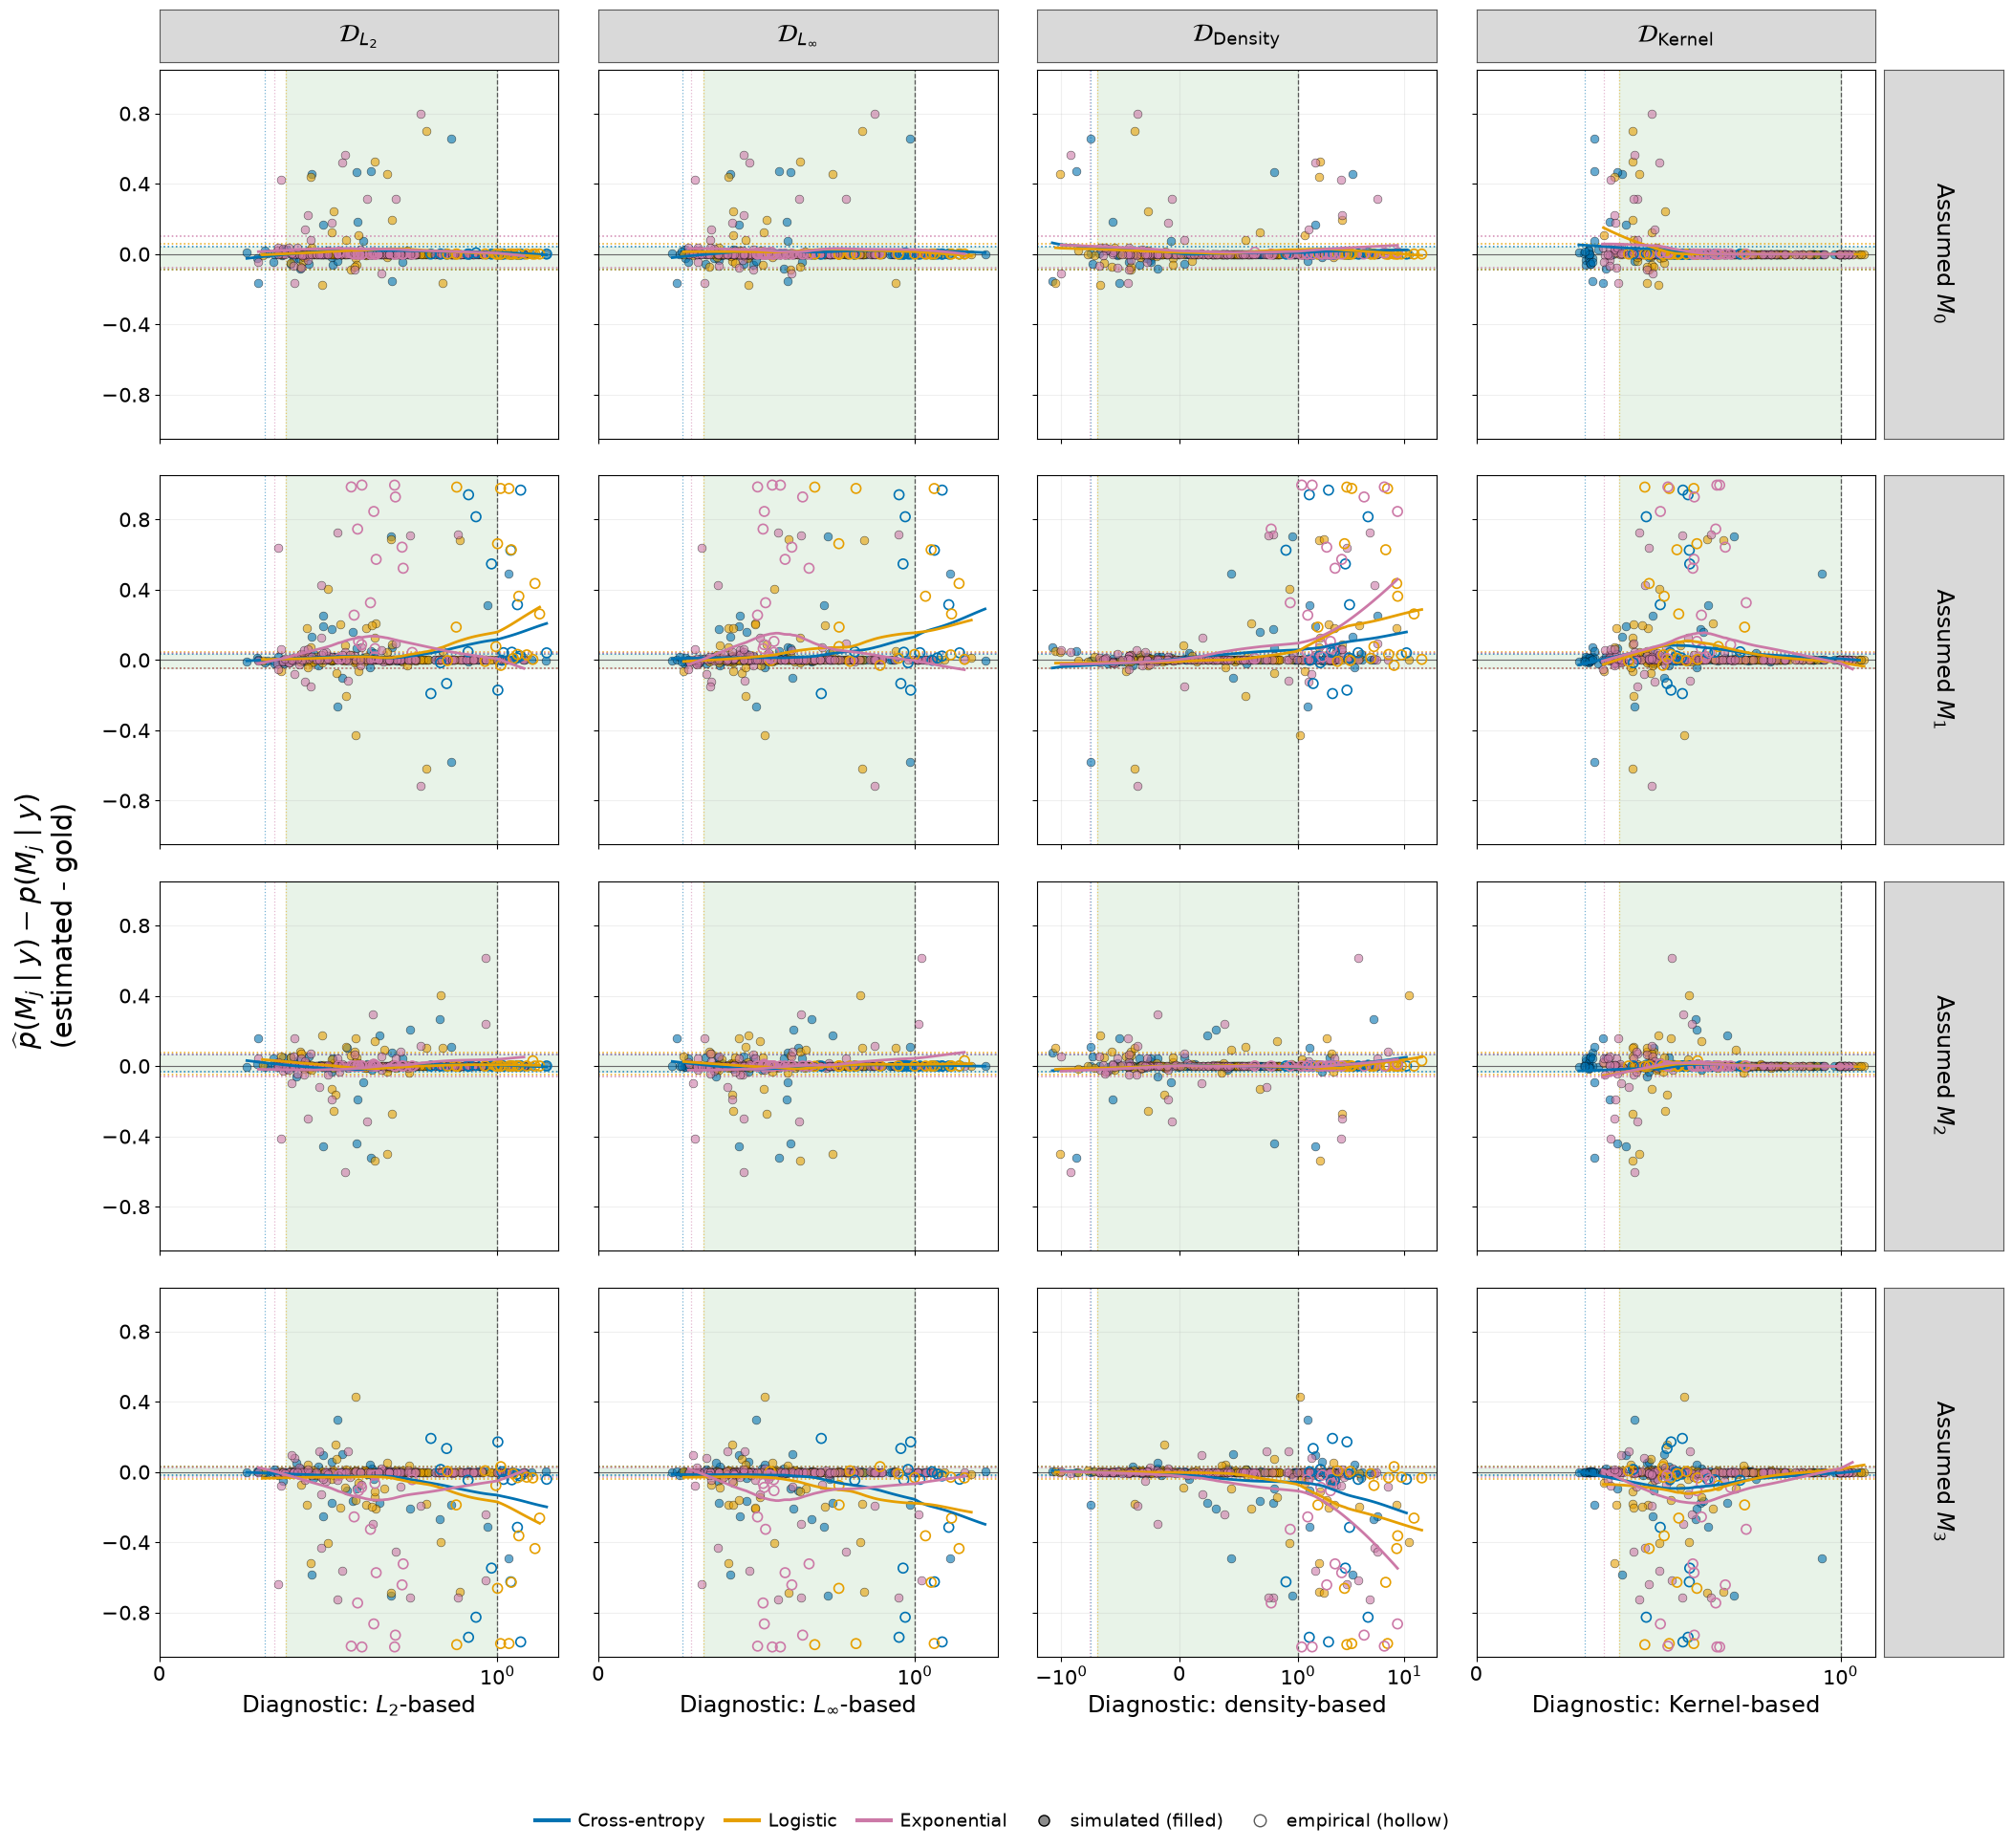

In [9]:
fig_direct, axes_direct = plot_metric_grid(
    direct_runs,
    "pmp",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "direct" / DATASET_TYPE / "pmp_error_4x4",
    ylim=(-1.05, 1.05),
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    dpi=DPI,
)
plt.show()


## Direct vs indirect PMP recovery


Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/recovery/both/pmp_recovery.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/recovery/both/pmp_recovery.pdf


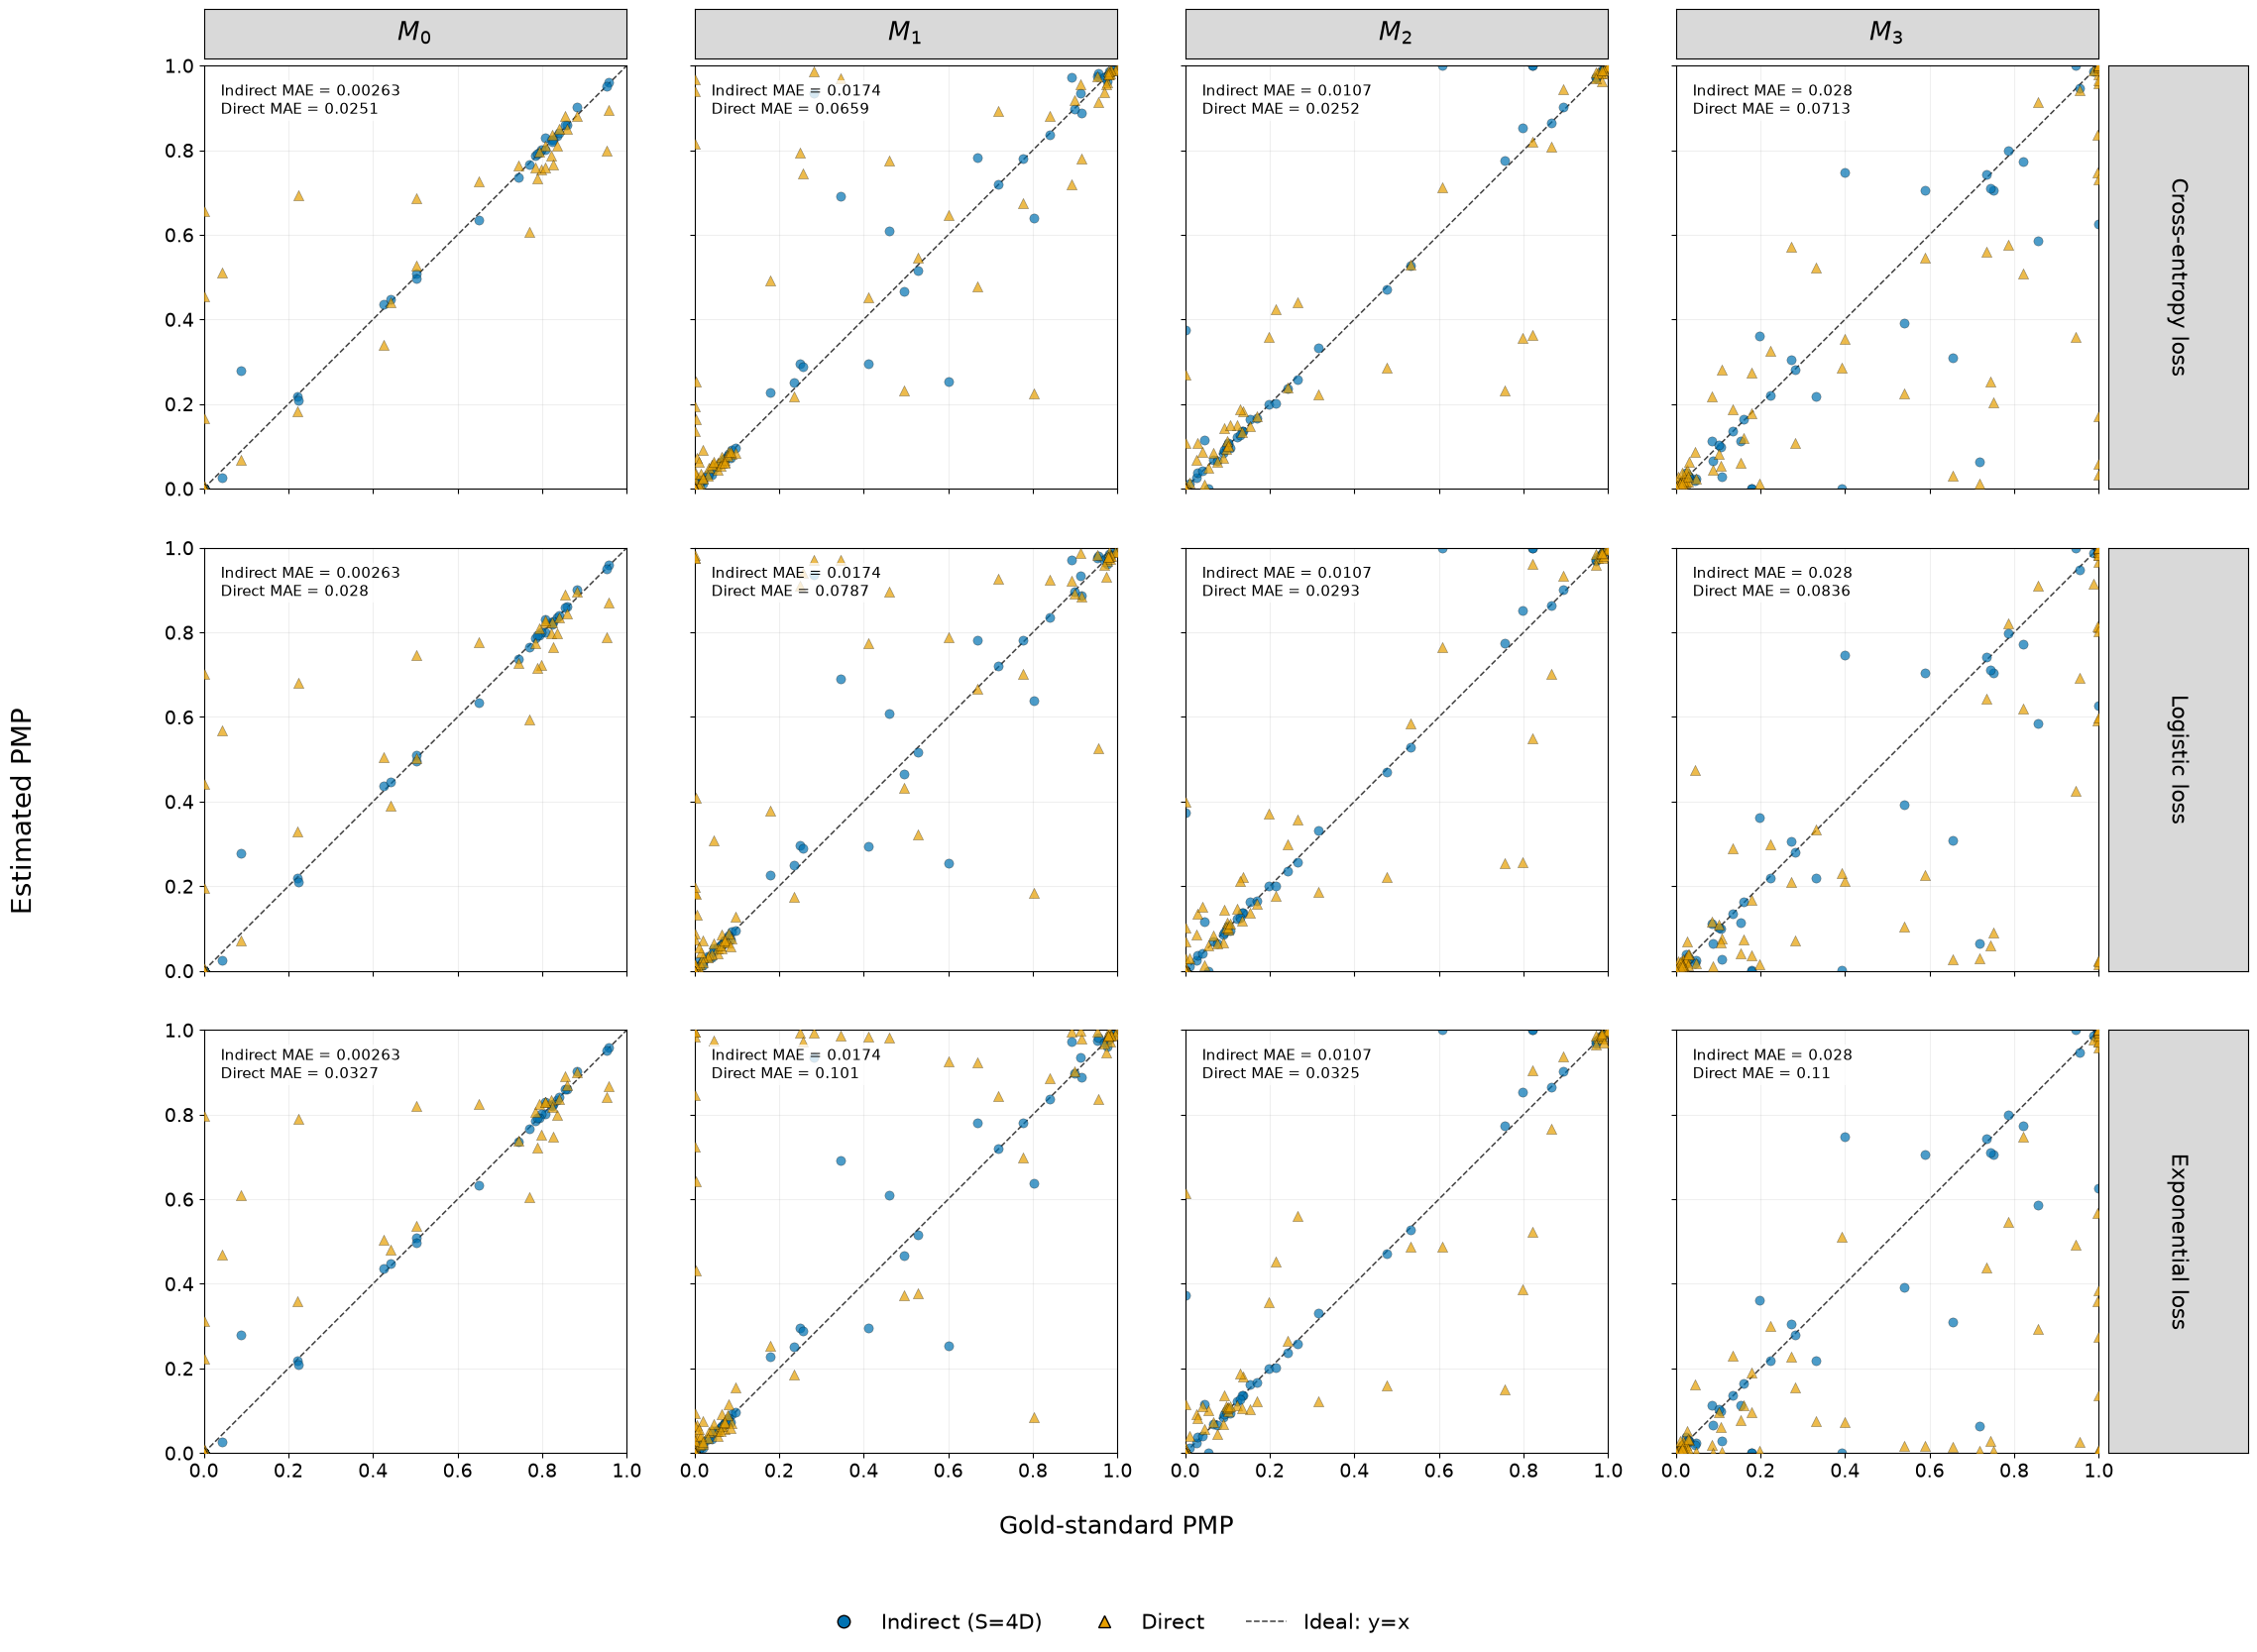

In [10]:
fig_recovery, axes_recovery = plot_pmp_recovery(
    indirect_runs,
    direct_runs,
    summary_multiplier=4,
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "recovery" / DATASET_TYPE / "pmp_recovery",
    dpi=DPI,
)
plt.show()


## Direct PMP errors outside the threshold band, by assumed and source model

The direct PMP plot uses simulated and empirical observations (`DATASET_TYPE="both"`). Each assumed model is a separate plot row and PMP component. For that row, the green horizontal band is the intersection of the Cross-entropy, Logistic, and Exponential thresholds: lower edge = maximum `pmp_error_lower`; upper edge = minimum `pmp_error_upper`. A valid `signed_pmp_error` outside either edge is counted. These counts use the shared green band drawn in the plot, rather than the individual scoring-rule threshold lines.

Each entry is the number of plotted points at **ρ ≤ 1 / ρ > 1** for the indicated diagnostic. Within one diagnostic, a point is one dataset × scoring rule × assumed model. The three scoring rules are pooled; the same dataset can contribute multiple points and can appear in multiple diagnostic columns. `empirical` has no known generating model.

| Assumed model | `source_model` | L2 (≤1 / >1) | L∞ (≤1 / >1) | Density (≤1 / >1) | Kernel (≤1 / >1) |
|---|---|---:|---:|---:|---:|
| `m0` | `simulated_from_m0` | 12 / 0 | 12 / 0 | 12 / 0 | 12 / 0 |
| `m0` | `simulated_from_m1` | 11 / 0 | 11 / 0 | 9 / 2 | 11 / 0 |
| `m0` | `simulated_from_m2` | 3 / 0 | 3 / 0 | 3 / 0 | 3 / 0 |
| `m0` | `simulated_from_m3` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| `m0` | `m3_fast_30` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| `m0` | `m3_fast_slow_30` | 10 / 0 | 10 / 0 | 1 / 9 | 10 / 0 |
| `m0` | `m3_slow_30` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| `m0` | `empirical` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| **m0 subtotal** |  | **36 / 0** | **36 / 0** | **25 / 11** | **36 / 0** |
| `m1` | `simulated_from_m0` | 3 / 0 | 3 / 0 | 3 / 0 | 3 / 0 |
| `m1` | `simulated_from_m1` | 17 / 0 | 17 / 0 | 13 / 4 | 17 / 0 |
| `m1` | `simulated_from_m2` | 3 / 0 | 3 / 0 | 3 / 0 | 3 / 0 |
| `m1` | `simulated_from_m3` | 5 / 1 | 5 / 1 | 5 / 1 | 6 / 0 |
| `m1` | `m3_fast_30` | 5 / 0 | 5 / 0 | 0 / 5 | 5 / 0 |
| `m1` | `m3_fast_slow_30` | 15 / 0 | 15 / 0 | 5 / 10 | 15 / 0 |
| `m1` | `m3_slow_30` | 7 / 0 | 7 / 0 | 1 / 6 | 7 / 0 |
| `m1` | `empirical` | 24 / 14 | 28 / 10 | 3 / 35 | 38 / 0 |
| **m1 subtotal** |  | **79 / 15** | **83 / 11** | **33 / 61** | **94 / 0** |
| `m2` | `simulated_from_m0` | 13 / 0 | 13 / 0 | 13 / 0 | 13 / 0 |
| `m2` | `simulated_from_m1` | 8 / 0 | 8 / 0 | 8 / 0 | 8 / 0 |
| `m2` | `simulated_from_m2` | 7 / 0 | 7 / 0 | 7 / 0 | 7 / 0 |
| `m2` | `simulated_from_m3` | 6 / 0 | 5 / 1 | 6 / 0 | 6 / 0 |
| `m2` | `m3_fast_30` | 1 / 0 | 1 / 0 | 0 / 1 | 1 / 0 |
| `m2` | `m3_fast_slow_30` | 9 / 0 | 9 / 0 | 2 / 7 | 9 / 0 |
| `m2` | `m3_slow_30` | 5 / 0 | 4 / 1 | 1 / 4 | 5 / 0 |
| `m2` | `empirical` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| **m2 subtotal** |  | **49 / 0** | **47 / 2** | **37 / 12** | **49 / 0** |
| `m3` | `simulated_from_m0` | 0 / 0 | 0 / 0 | 0 / 0 | 0 / 0 |
| `m3` | `simulated_from_m1` | 16 / 0 | 16 / 0 | 12 / 4 | 16 / 0 |
| `m3` | `simulated_from_m2` | 4 / 0 | 4 / 0 | 4 / 0 | 4 / 0 |
| `m3` | `simulated_from_m3` | 11 / 1 | 10 / 2 | 11 / 1 | 12 / 0 |
| `m3` | `m3_fast_30` | 12 / 0 | 12 / 0 | 1 / 11 | 12 / 0 |
| `m3` | `m3_fast_slow_30` | 19 / 0 | 19 / 0 | 6 / 13 | 19 / 0 |
| `m3` | `m3_slow_30` | 15 / 0 | 14 / 1 | 2 / 13 | 15 / 0 |
| `m3` | `empirical` | 26 / 19 | 32 / 13 | 4 / 41 | 45 / 0 |
| **m3 subtotal** |  | **103 / 20** | **107 / 16** | **40 / 83** | **123 / 0** |

At ρ > 1, L2 out-of-band points occur only in assumed `m1` (15) and `m3` (20); 33 of these 35 points are empirical and two are from `simulated_from_m3`. L∞ out-of-band points occur in assumed `m1` (11), `m2` (2), and `m3` (16). Density out-of-band points occur in all four assumed models (`m0`: 11, `m1`: 61, `m2`: 12, `m3`: 83). Kernel has ρ > 1 points but none outside the band.

Counts are plot points, not distinct datasets or measures of statistical significance.
